TASK-1: DATA CLEANING PREPROCESSING AND VISUALIZATION

In [144]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [145]:
df=pd.read_csv("/content/archive (1).zip")

In [146]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [147]:
df.columns


Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [148]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [149]:
median_age=df['Age'].median()
df['Age']=df['Age'].fillna(median_age)


In [150]:
df.isnull().sum()


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [151]:
df['Has_cabin']=np.where(df['Cabin'].isna(),0,1)
df=df.drop(columns=['Cabin'])

In [152]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Has_cabin
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,1
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,0


In [153]:
most_common_port=df['Embarked'].mode()[0]
df['Embarked']=df['Embarked'].fillna(most_common_port)
df.head()
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


data has no null values now


In [154]:
df.duplicated().sum()

np.int64(0)

Handling categorial data

In [155]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder,MinMaxScaler,StandardScaler
encoder=OneHotEncoder()


In [156]:
df_encoded=encoder.fit_transform(df[['Sex','Embarked','Pclass']])
encoded_df=pd.DataFrame(df_encoded.toarray(),columns=encoder.get_feature_names_out(['Sex','Embarked','Pclass']))
df_processed=pd.concat([df[['Age','Fare','SibSp']], encoded_df],axis=1)


In [157]:
age_scaler=StandardScaler()
df_processed['Age']=age_scaler.fit_transform(df_processed[['Age']])
fare_scaler=StandardScaler()
df_processed['Fare']=fare_scaler.fit_transform(df_processed[['Fare']])
df_processed.head()

,Age,Fare,SibSp,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Pclass_1,Pclass_2,Pclass_3
0,-0.565736,-0.502445,1,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
1,0.663861,0.786845,1,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,-0.258337,-0.488854,0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
3,0.433312,0.420730,1,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
4,0.433312,-0.486337,0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0


In [158]:
q1 = df_processed['Age'].quantile(0.25)
q3 = df_processed['Age'].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = df_processed[(df_processed['Age'] < lower_bound) | (df_processed['Age'] > upper_bound)]

print(f"IQR: {iqr}")
print(f"Lower Bound: {lower_bound}")
print(f"Upper Bound: {upper_bound}")
print(f"Number of outliers found: {len(outliers)}")
display(outliers.head())

IQR: 0.9990479631767853
Lower Bound: -2.0643084058400527
Upper Bound: 1.9318834468670887
Number of outliers found: 66


,Age,Fare,SibSp,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Pclass_1,Pclass_2,Pclass_3
7,-2.102733,-0.224083,3,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
11,2.200858,-0.113846,0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
15,1.970308,-0.326267,0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
16,-2.102733,-0.061999,4,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
33,2.815657,-0.437007,0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0


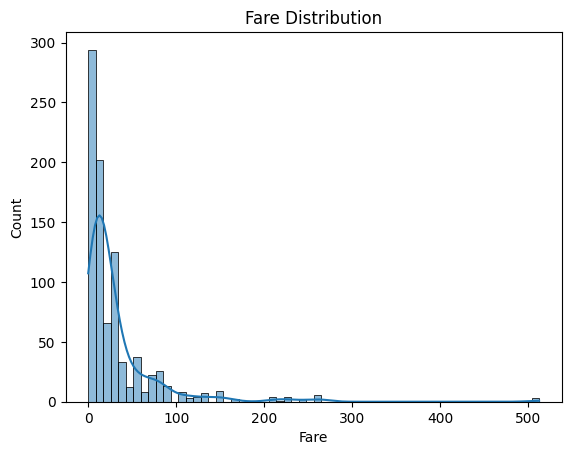

In [168]:


sns.histplot(df['Fare'], kde=True).set_title('Fare Distribution')

plt.show()

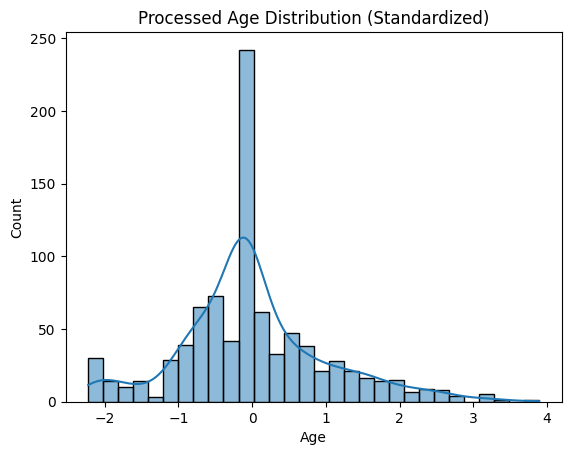

In [164]:
sns.histplot(df_processed['Age'], kde=True).set_title('Processed Age Distribution (Standardized)')
plt.show()

/tmp/ipykernel_1820/2069101223.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Sex',palette='magma').set_title('Gender Count')


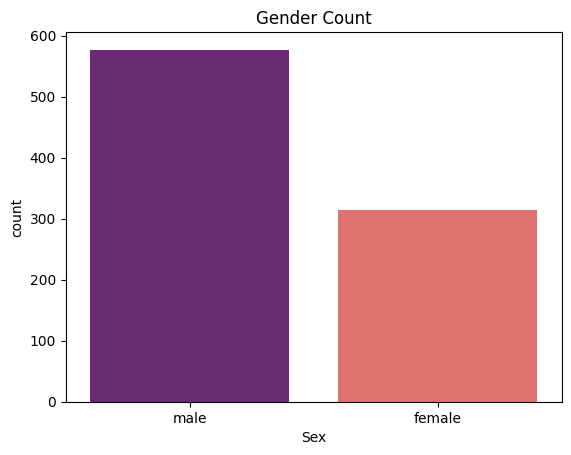

In [166]:
sns.countplot(data=df, x='Sex',palette='magma').set_title('Gender Count')
plt.show()

In [169]:
# Calculate IQR bounds for the 'Fare' feature
q1_fare = df_processed['Fare'].quantile(0.25)
q3_fare = df_processed['Fare'].quantile(0.75)
iqr_fare = q3_fare - q1_fare

lower_bound_fare = q1_fare - 1.5 * iqr_fare
upper_bound_fare = q3_fare + 1.5 * iqr_fare

print(f"Original Fare Outlier Limits: {lower_bound_fare} to {upper_bound_fare}")
print(f"Number of outliers before capping: {len(df_processed[(df_processed['Fare'] < lower_bound_fare) | (df_processed['Fare'] > upper_bound_fare)])}")

# Minimize outliers by capping (Winsorization)
df_processed['Fare'] = df_processed['Fare'].clip(lower=lower_bound_fare, upper=upper_bound_fare)

print(f"Number of outliers after capping: {len(df_processed[(df_processed['Fare'] < lower_bound_fare) | (df_processed['Fare'] > upper_bound_fare)])}")
display(df_processed['Fare'].describe())

Original Fare Outlier Limits: -1.18650103391317 to 0.6731064591401562
Number of outliers before capping: 116
Number of outliers after capping: 0


,Fare
count,891.000000
mean,-0.164247
std,0.412391
min,-0.648422
25%,-0.489148
50%,-0.357391
75%,-0.024246
max,0.673106


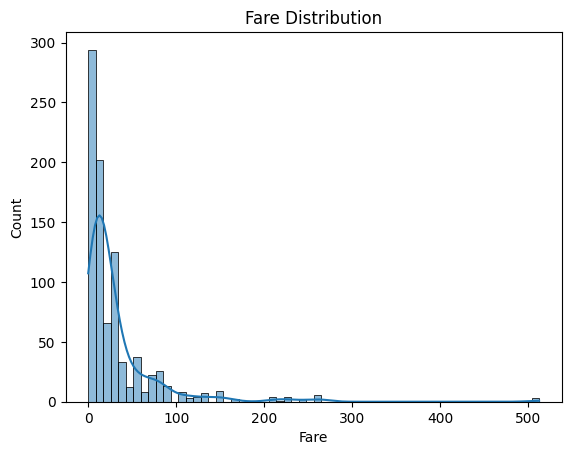

In [170]:

sns.histplot(df['Fare'], kde=True).set_title('Fare Distribution')

plt.show()